First five rows:
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB

Statistical Description:
       buying  maint doors persons lug_boot safety  class
count    1728   1728  1728    1728     1728   1728   1728
unique      

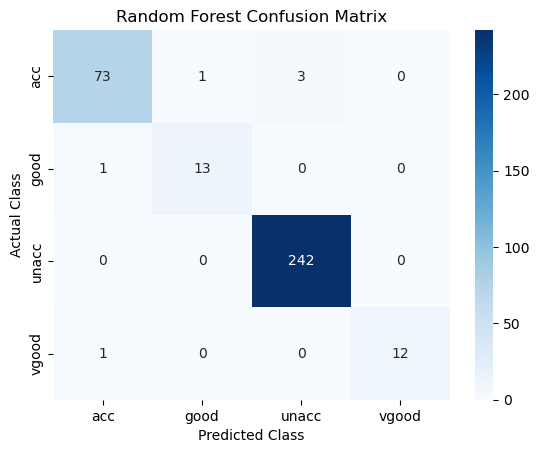


Feature Importance:
safety      0.277857
persons     0.223212
buying      0.183894
maint       0.158944
lug_boot    0.086729
doors       0.069363
dtype: float64


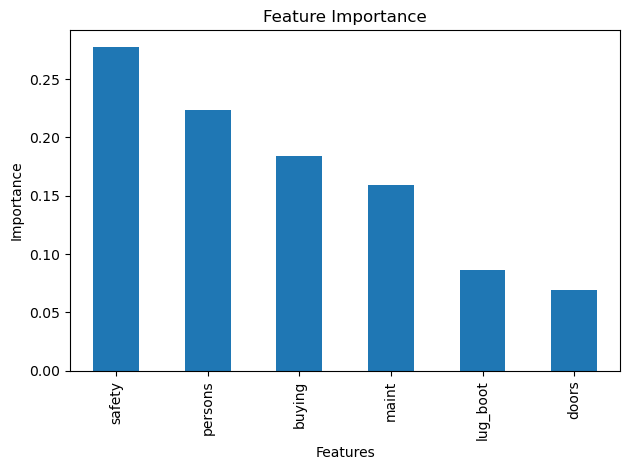

In [1]:
# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Step 2: Load the Car Evaluation dataset
columns = [
    'buying', 'maint', 'doors',
    'persons', 'lug_boot', 'safety', 'class'
]

data = pd.read_csv('car_evaluation.csv')

# Check whether the CSV already contains column headers
if not set(columns).issubset(set(data.columns)):
    data = pd.read_csv('car_evaluation.csv', header=None, names=columns)
else:
    data = data[columns]

# Step 3: Explore the dataset
print("First five rows:")
print(data.head())

print("\nDataset Information:")
data.info()

print("\nStatistical Description:")
print(data.describe(include='all'))

# Step 4: Check for missing values
print("\nMissing Values:")
print(data.isnull().sum())

# Remove duplicate rows, if any
data = data.drop_duplicates()

# Handle missing categorical values, if any
for col in columns:
    data[col] = data[col].fillna(data[col].mode()[0])

# Step 5: Separate features and target
X = data.drop('class', axis=1)
y = data['class']

# Step 6: Encode categorical input features into numbers
encoder = OrdinalEncoder()
X_encoded = encoder.fit_transform(X)

# Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("\nEncoded Target Classes:")
print(label_encoder.classes_)

# Step 7: Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Step 8: Create the Random Forest Classifier
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Step 9: Train the model
model.fit(X_train, y_train)

# Step 10: Predict the test data
y_pred = model.predict(X_test)

# Step 11: Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("\nRandom Forest Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

# Step 12: Display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest Confusion Matrix")
plt.show()

# Step 13: Display feature importance
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nFeature Importance:")
print(importance)

importance.plot(kind='bar', title='Feature Importance')
plt.xlabel("Features")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()